In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
df = pd.read_csv("C:\\Users\\atavu-tech\\Desktop\\AI Gen\\Student Performance Project\\student_performance.csv")
df

,Student_ID,Student_Name,Class,Math_Score,English_Score,Science_Score,Attendance_Percent,P.E Activities,Total
0,ST001,Gardiner Dowsett,SS1,46,82,42,95,48,313
1,ST002,Robbie Denecamp,SS1,53,71,51,88,63,326
2,ST003,Michal Prattin,SS3,48,55,43,70,71,287
3,ST004,Stavro Ife,SS1,49,86,33,98,50,316
4,ST005,Ernst Minter,SS1,52,62,52,80,45,291
...,...,...,...,...,...,...,...,...,...
94,ST095,Ailee Wreford,SS3,51,58,60,96,71,336
95,ST096,Pollyanna Batecok,SS1,55,68,51,93,50,317
96,ST097,Woodie Leathlay,SS3,60,87,56,87,43,333
97,ST098,Devlin Weaving,SS2,60,53,44,84,79,320


In [21]:
#first five rows
print(df.head())

#number of rows and columns
print(df.shape)

#column names and data types
print(df.info())


  Student_ID      Student_Name Class  Math_Score  English_Score  \
0      ST001  Gardiner Dowsett   SS1          46             82   
1      ST002   Robbie Denecamp   SS1          53             71   
2      ST003    Michal Prattin   SS3          48             55   
3      ST004        Stavro Ife   SS1          49             86   
4      ST005      Ernst Minter   SS1          52             62   

   Science_Score  Attendance_Percent  P.E Activities   Total  
0             42                  95              48     313  
1             51                  88              63     326  
2             43                  70              71     287  
3             33                  98              50     316  
4             52                  80              45     291  
(99, 9)
<class 'pandas.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Student_ID          9

In [22]:
#for missing values
print("Missing values:")
print(df.isnull().sum())

#for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

#the dataset structure
print(df.dtypes)


Missing values:


Student_ID            0
Student_Name          0
Class                 0
Math_Score            0
English_Score         0
Science_Score         0
Attendance_Percent    0
P.E Activities        0
 Total                0
dtype: int64
Duplicate rows: 0
Student_ID              str
Student_Name            str
Class                   str
Math_Score            int64
English_Score         int64
Science_Score         int64
Attendance_Percent    int64
P.E Activities        int64
 Total                int64
dtype: object


In [23]:
subjects = ["Math_Score", "English_Score", "Science_Score", "P.E Activities"]

df["Average_Score"] = df[subjects].mean(axis=1)  # what does axis do here


df["Result"] = df["Average_Score"].apply(
    lambda score: "Pass" if score >= 70 else "Needs Support"
)

print(df[["Student_ID", "Average_Score", "Result"]])



   Student_ID  Average_Score         Result
0       ST001          54.50  Needs Support
1       ST002          59.50  Needs Support
2       ST003          54.25  Needs Support
3       ST004          54.50  Needs Support
4       ST005          52.75  Needs Support
..        ...            ...            ...
94      ST095          60.00  Needs Support
95      ST096          56.00  Needs Support
96      ST097          61.50  Needs Support
97      ST098          59.00  Needs Support
98      ST099          55.25  Needs Support

[99 rows x 3 columns]


In [24]:
# average score
print("Overall average:", df["Average_Score"].mean())

# average score by subject
print(df[subjects].mean())

# percentage of students who passed
pass_rate = (df["Result"] == "Pass").mean() * 100
print("Pass rate:", round(pass_rate, 2), "%")

# average attendance
print(
    "Average attendance:",
    round(df["Attendance_Percent"].mean(), 2), "%" \
    ""
)

# students who may need additional support
support = df[df["Average_Score"] < 50]

print("Students needing support:")
print(support[["Student_ID", "Average_Score"]])


Overall average: 55.31818181818182
Math_Score        52.030303
English_Score     62.393939
Science_Score     45.616162
P.E Activities    61.232323
dtype: float64
Pass rate: 0.0 %
Average attendance: 79.42 %
Students needing support:
   Student_ID  Average_Score
6       ST007          47.25
9       ST010          49.00
14      ST015          46.50
15      ST016          49.00
19      ST020          48.25
23      ST024          49.25
24      ST025          46.25
28      ST029          44.75
29      ST030          45.75
32      ST033          49.75
43      ST044          47.25
48      ST049          48.50
64      ST065          47.25
67      ST068          48.50
70      ST071          47.00
72      ST073          49.00
78      ST079          48.25
79      ST080          47.25
85      ST086          47.50
86      ST087          49.50
91      ST092          48.75


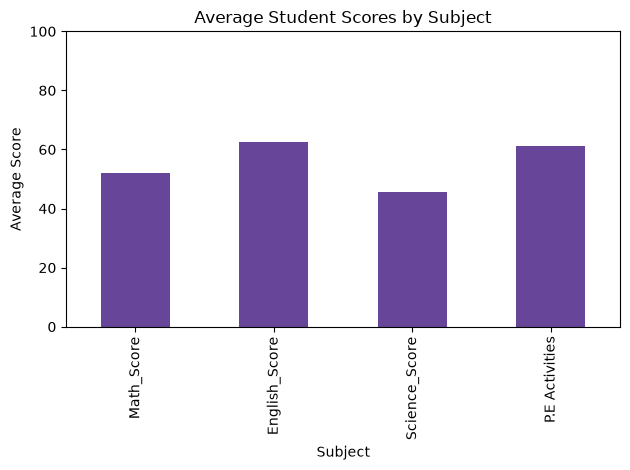

In [26]:
subject_averages = df[subjects].mean()

subject_averages.plot(kind="bar", color="#674598")

plt.title("Average Student Scores by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Score")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [ ]:
df.to_csv("student_performance_analyzed.csv", index=False)

print("Analysis saved successfully!")

Analysis saved successfully!
